In [1]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [2]:
df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()

In [3]:
df_DA

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
12,Data Analyst,Stagiaire Data Analyst (H/F) - Lyon (69006),"Lyon, France",via Jobijoba,Full-time and Internship,False,France,2023-12-22 13:24:41,False,False,France,NaN,NaN,NaN,Engie,"['sql', 'php', 'excel', 'power bi', 'sap', 'ji...","{'analyst_tools': ['excel', 'power bi', 'sap']..."
18,Data Analyst,Data Analyst,"Warsaw, Poland",via Praca Trabajo.org,Full-time,False,Poland,2023-10-16 13:36:54,False,False,Poland,NaN,NaN,NaN,Glovo,"['sql', 'python', 'r', 'redshift', 'pandas', '...","{'analyst_tools': ['excel', 'looker', 'tableau..."
31,Data Analyst,Stage - Data Analyst F/H,"Paris, France",via LinkedIn,Full-time and Internship,False,France,2023-10-19 13:59:31,False,False,France,NaN,NaN,NaN,GROUPE BON MARCHÉ : Le Bon Marché Rive Gauche ...,['sql'],{'programming': ['sql']}
34,Data Analyst,Data Analyst als Marketing Manager Automation ...,"Erlangen, Germany",via Central Illinois Proud Jobs,Full-time,False,Germany,2023-02-23 13:31:28,True,False,Germany,NaN,NaN,NaN,DEFACTO GmbH,['sap'],{'analyst_tools': ['sap']}
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785703,Data Analyst,Data Analyst - CRYPTOGRAPHY - Full-time,Anywhere,via Snagajob,Full-time,True,"Texas, United States",2023-01-28 06:02:55,True,False,United States,NaN,NaN,NaN,Axelon Services Corporation,NaN,NaN
785705,Data Analyst,Expert Business Data Analyst - Now Hiring,"Oakland, CA",via Snagajob,Full-time,False,"California, United States",2023-01-09 06:00:25,False,False,United States,NaN,NaN,NaN,PG&E Corporation,"['sql', 'python', 'tableau']","{'analyst_tools': ['tableau'], 'programming': ..."
785715,Data Analyst,Amul Careers 2023 - Apply Online - Data Analys...,India,melalui Jobsleworld - Jobs In India - Job Vaca...,Pekerjaan tetap,False,India,2023-03-13 06:16:28,False,False,India,NaN,NaN,NaN,Amul,NaN,NaN
785717,Data Analyst,Data & Analytics Architect (w/m/x),"Erfurt, Jerman",melalui LinkedIn,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,NTT DATA DACH,"['aws', 'azure']","{'cloud': ['aws', 'azure']}"


In [6]:
df_DA['job_posted_month_no'] = df_DA['job_posted_date'].dt.month

df_DA_explode = df_DA.explode('job_skills')

df_DA_pivot = df_DA_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

In [10]:
df_DA_pivot.loc['total'] = df_DA_pivot.sum()

df_DA_pivot = df_DA_pivot[df_DA_pivot.loc['total'].sort_values(ascending=False).index]

df_DA_pivot = df_DA_pivot.drop('total')

In [11]:
df_DA_pivot

job_skills,['excel'],['sql'],"['sql', 'excel']",['sap'],"['sql', 'python']",['power bi'],"['sql', 'tableau']",['go'],['tableau'],"['sql', 'power bi']",...,"['word', 'spreadsheet', 'excel', 'spss']","['word', 'spreadsheet', 'excel', 'terminal']","['word', 'spreadsheet', 'jira']","['word', 'spreadsheet', 'powerpoint', 'excel']","['word', 'tableau']","['word', 'terminal', 'zoom']","['word', 'qlik', 'power bi']","['word', 'sap', 'tableau', 'alteryx']","['alteryx', 'power bi', 'word', 'excel', 'powerpoint']","['alteryx', 'qlik', 'sap', 'excel']"
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,965,640,381,178,169,178,212,149,163,107,...,0,0,0,0,0,1,0,0,0,0
2,683,434,288,136,135,132,118,89,124,82,...,1,0,0,0,0,0,0,0,0,0
3,648,468,285,115,116,122,151,103,135,77,...,0,0,0,0,1,0,0,0,0,0
4,568,372,354,126,108,114,105,96,107,84,...,0,1,0,0,0,0,0,0,0,0
5,538,327,242,127,114,87,105,98,77,57,...,0,0,0,0,0,0,0,0,0,0
6,691,410,270,184,126,157,104,113,77,88,...,0,0,0,0,0,0,0,0,0,0
7,611,406,192,167,134,165,102,106,87,75,...,0,0,0,0,0,0,0,1,0,1
8,840,446,239,166,151,160,124,114,116,99,...,0,0,0,0,0,0,0,0,0,0
9,582,380,213,120,161,102,86,120,79,83,...,0,0,0,0,0,0,0,0,0,0


<Axes: xlabel='job_posted_month_no'>

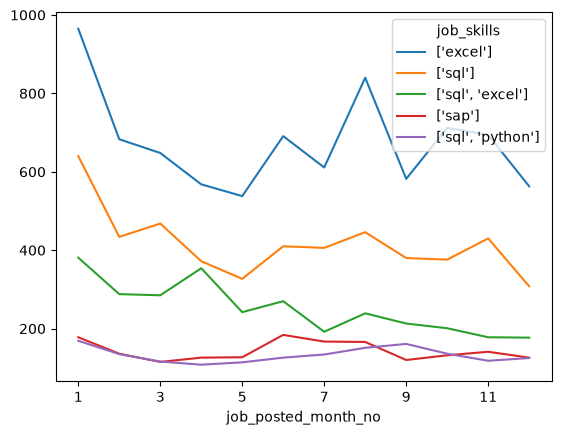

In [12]:
df_DA_pivot.iloc[:, :5].plot(kind="line")